In [1]:
import matplotlib as plt
import matplotlib.pyplot as pyplt
import numpy as np
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import pandas as pd

from pathlib import Path

from slide_datatypes import difficulty_colours, SlidePattern, ChartDifficulty
from base_slide_dataset import full_df, pruned_df

In [2]:
mas_remas_df = pruned_df[(pruned_df['difficulty'] == 5) | (pruned_df['difficulty'] == 6)]
mas_remas_outlier_removed_df = mas_remas_df[(np.abs(stats.zscore(mas_remas_df['star_duration'])) < 3) & (np.abs(stats.zscore(mas_remas_df['slide_duration'])) < 3)]
mas_remas_straight_slide_df = mas_remas_outlier_removed_df[mas_remas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
mas_remas_across_straight_slide_df = mas_remas_straight_slide_df[mas_remas_straight_slide_df['cw_distance'] == 4]
len(mas_remas_across_straight_slide_df)

sdt_mas_remas_across_straight_slide_df = mas_remas_across_straight_slide_df[mas_remas_across_straight_slide_df['version'] == 'sdt']
sdt_mas_remas_across_straight_slide_df

,star_duration,slide_duration,slide_delay,cw_distance,pattern_group,bpm,difficulty,difficulty_constant,version,song_id,duration_ratio,duration_with_delay,duration_with_delay_ratio
182,0.1157,0.3750,0.25,4,1,140.0,6,13.7,sdt,22,0.308533,0.6250,0.185120
248,0.1157,0.3750,0.25,4,1,125.0,6,12.9,sdt,23,0.308533,0.6250,0.185120
257,0.1250,0.3750,0.25,4,1,125.0,6,12.9,sdt,23,0.333333,0.6250,0.200000
284,0.0579,0.3125,0.25,4,1,125.0,6,12.9,sdt,23,0.185280,0.5625,0.102933
391,0.3472,0.6250,0.25,4,1,125.0,6,12.9,sdt,23,0.555520,0.8750,0.396800
...,...,...,...,...,...,...,...,...,...,...,...,...,...
119208,0.3205,0.6250,0.25,4,1,220.0,5,12.8,sdt,849,0.512800,0.8750,0.366286
119522,0.0977,0.3750,0.25,4,1,200.0,5,13.0,sdt,850,0.260533,0.6250,0.156320
119567,0.1157,0.3750,0.25,4,1,200.0,5,13.0,sdt,850,0.308533,0.6250,0.185120
119758,0.1157,0.3750,0.25,4,1,215.0,5,13.2,sdt,852,0.308533,0.6250,0.185120


## Get linear coefficients for each chart on straight slides

In [3]:
sdt_straight_slide_per_mas_remas_with_bpm = sdt_mas_remas_across_straight_slide_df.dropna(subset=['bpm', 'difficulty', 'song_id'])
sdt_straight_slide_per_mas_remas_with_bpm = sdt_straight_slide_per_mas_remas_with_bpm[sdt_straight_slide_per_mas_remas_with_bpm['bpm'] != 0]

sdt_straight_slide_per_mas_remas_with_bpm['slide_duration_over_bpm'] = sdt_straight_slide_per_mas_remas_with_bpm['slide_duration'] / sdt_straight_slide_per_mas_remas_with_bpm['bpm']
sdt_straight_slide_per_mas_remas_with_bpm['bpm_over_slide_duration'] = sdt_straight_slide_per_mas_remas_with_bpm['bpm'] / sdt_straight_slide_per_mas_remas_with_bpm['slide_duration']

sdt_straight_slide_per_mas_remas = sdt_straight_slide_per_mas_remas_with_bpm.groupby(['song_id', 'difficulty'])


# sdt_straight_slide_per_mas_remas_with_bpm[sdt_straight_slide_per_mas_remas_with_bpm['bpm'] < 30]

In [46]:
sdt_straight_slide_per_mas_remas_models = []

for chart_params, chart_slides in sdt_straight_slide_per_mas_remas:
    if len(chart_slides) < 2:
        continue
    
    X = chart_slides[['slide_duration']]
    y = chart_slides[['star_duration']]

    # Add a constant column to the independent variables
    X = sm.add_constant(X)

    # Fit the multiple linear regression model
    raw_model = sm.OLS(y, X).fit()
    
    bpm_adjusted_X = chart_slides[['slide_duration_over_bpm']]
    
    inverse_bpm_adjusted_X = chart_slides[['bpm_over_slide_duration']]
    
    bpm_adjusted_X = sm.add_constant(bpm_adjusted_X)
    
    bpm_adjusted_model = sm.OLS(y, bpm_adjusted_X).fit()
    
    inverse_bpm_adjusted_model = sm.OLS(y, inverse_bpm_adjusted_X).fit()
    
    # print(raw_model.params)
    
    if 'const' in raw_model.params:
        raw_const = raw_model.params['const']
    else:
        raw_const = 0
    if 'const' in bpm_adjusted_model.params:
        bpm_adjusted_const = bpm_adjusted_model.params['const']
    else:
        bpm_adjusted_const = 0
    if 'const' in inverse_bpm_adjusted_model.params:
        inverse_bpm_adjusted_const = inverse_bpm_adjusted_model.params['const']
    else:
        inverse_bpm_adjusted_const = 0
    row = {
        'song_id': chart_params[0],
        'difficulty': chart_params[1],
        'bpm': chart_slides.bpm.iloc[0],
    
        'raw_slide_duration': raw_model.params['slide_duration'],
        'raw_const': 0,
        
        'raw_intervals': raw_model.conf_int(),
        
        'bpm_adjusted_duration': 0 if 'slide_duration' not in bpm_adjusted_model.params else bpm_adjusted_model.params['slide_duration'],
        'bpm_adjusted_const': bpm_adjusted_const,
        'bpm_adjusted_intervals': bpm_adjusted_model.conf_int(),
        
        'inverse_bpm_adjusted_duration': 0 if 'slide_duration' not in inverse_bpm_adjusted_model.params else inverse_bpm_adjusted_model.params['slide_duration'],
        'inverse_bpm_adjusted_const': inverse_bpm_adjusted_const,
        'inverse_bpm_adjusted_intervals': inverse_bpm_adjusted_model.conf_int(),
        
    }
    
    sdt_straight_slide_per_mas_remas_models.append(row)
    
models_df = pd.DataFrame(sdt_straight_slide_per_mas_remas_models)
models_df.to_json(Path('mas_remas_straight_slide_models.json'), indent=2)
# sdt_straight_slide_per_mas_remas

c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\P

In [47]:
models_df

,song_id,difficulty,bpm,raw_slide_duration,raw_const,raw_intervals,bpm_adjusted_duration,bpm_adjusted_const,bpm_adjusted_intervals,inverse_bpm_adjusted_duration,inverse_bpm_adjusted_const,inverse_bpm_adjusted_intervals
0,23,6,125.0,0.918292,0,0 1 const ...,0,-0.225954,0 ...,0,0,0 1 bpm...
1,24,6,102.0,1.017157,0,0 1 const ...,0,-0.260010,0 1...,0,0,0 1 bp...
2,58,6,142.0,0.320933,0,0 1 slide_durati...,0,0.000000,0 1 ...,0,0,0 1 bp...
3,61,6,140.0,0.877200,0,0 1 const ...,0,-0.188850,0 1...,0,0,0 1 bp...
4,65,6,138.0,0.889200,0,0 1 const ...,0,-0.213100,0 1 ...,0,0,0 1 bp...
...,...,...,...,...,...,...,...,...,...,...,...,...
203,847,5,185.0,0.926400,0,0 1 const NaN NaN ...,0,-0.231700,0 1 const ...,0,0,0 1 bpm...
204,848,5,165.0,1.004267,0,0 1 const ...,0,-0.270633,0 1 ...,0,0,0 1 bp...
205,849,5,220.0,0.748373,0,0 1 const ...,0,-0.147667,0 ...,0,0,0 1 bp...
206,850,5,200.0,0.284533,0,0 1 slide_durat...,0,0.000000,0 1 ...,0,0,0 1 bp...


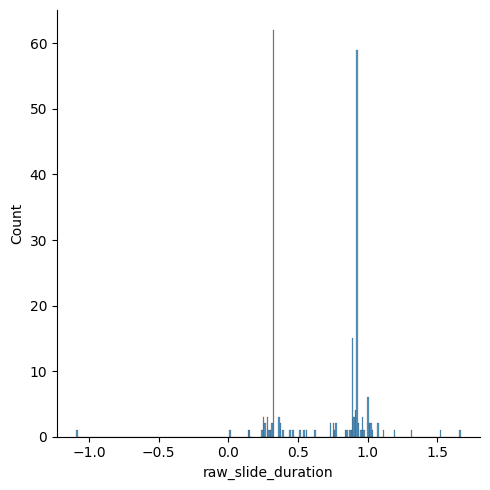

In [21]:
sns.displot(models_df, x="raw_slide_duration", binwidth=0.01)

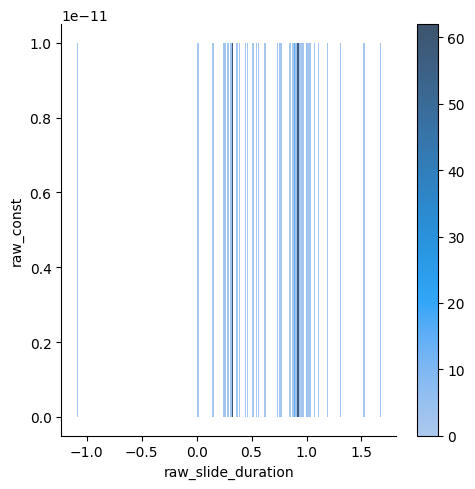

In [ ]:
sns.displot(models_df, x="raw_slide_duration", y='raw_const', binwidth=(0.01, 0.01), cbar=True)

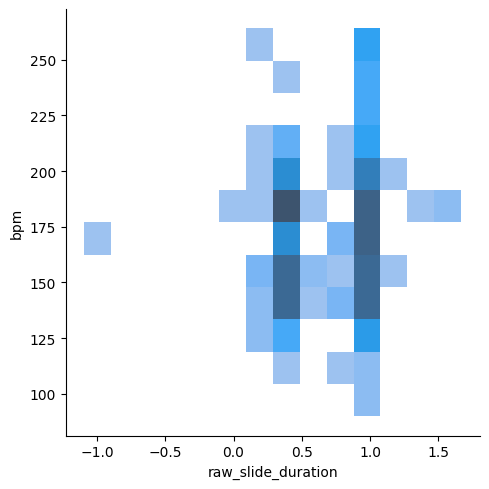

In [48]:
sns.displot(models_df, x="raw_slide_duration", y='bpm')

## TODO: Place coefficients divided by BPM to check for linear correlation between the two

Constant always found to be zero - model more in line with expectations (although coefficient for slide duration is still highly variable)